In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
rng = np.random.default_rng(42)

# Feature 1: Random values
f1 = rng.normal(0, 1, 300)

# Feature 2: Strongly correlated with Feature 1
f2 = f1 * 0.9 + rng.normal(0, 0.3, 300)

# Feature 3: Weakly correlated with Feature 1
f3 = f1 * 0.2 + rng.normal(0, 1, 300)

# Feature 4: Independent random values
f4 = rng.normal(0, 1, 300)

# Combine all four features
X = np.column_stack([f1, f2, f3, f4])

print(X.shape)
print(X[:5])

(300, 4)
[[ 0.30471708  0.79245044  0.57635382  0.38969171]
 [-1.03998411 -1.39614412 -0.78553571  0.10255318]
 [ 0.7504512   0.93455448  1.42453746 -0.14744249]
 [ 0.94056472  0.74795068 -0.43947459  1.58827611]
 [-1.95103519 -1.77432897 -1.02682232 -0.62220745]]


In [4]:
# Calculate mean of every column
mean = np.mean(X, axis=0)

# Calculate standard deviation of every column
std = np.std(X, axis=0, ddof=1)

# Standardise the dataset
Xs = (X - mean) / std

print("Means:", np.mean(Xs, axis=0))
print("Standard deviations:", np.std(Xs, axis=0, ddof=1))

print(np.allclose(np.mean(Xs, axis=0), 0))
print(np.allclose(np.std(Xs, axis=0, ddof=1), 1))

Means: [9.25185854e-19 1.30451205e-17 1.77635684e-17 6.58732328e-17]
Standard deviations: [1. 1. 1. 1.]
True
True


In [6]:
# Number of samples
n = Xs.shape[0]

# Calculate covariance matrix
cov_matrix = (Xs.T @ Xs) / (n - 1)

print(cov_matrix)
print("Shape:", cov_matrix.shape)
print(np.allclose(cov_matrix, cov_matrix.T))

[[ 1.          0.94092333  0.11009445  0.0263702 ]
 [ 0.94092333  1.          0.05923483 -0.01133345]
 [ 0.11009445  0.05923483  1.          0.03264394]
 [ 0.0263702  -0.01133345  0.03264394  1.        ]]
Shape: (4, 4)
True


In [8]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)
# Get indices that would sort eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

# Reorder eigenvalues
eigenvalues = eigenvalues[sorted_indices]

# Reorder corresponding eigenvectors
eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues:")
print(eigenvalues)

Eigenvalues:
[0.05700728 0.96060016 1.02623593 1.95615664]

Eigenvectors:
[[ 0.70814234 -0.05333495 -0.03224123 -0.70331381]
 [-0.70455788 -0.07083172 -0.09515891 -0.69966124]
 [-0.03748456  0.7744781   0.61902413 -0.12485075]
 [-0.02697294 -0.62635607  0.77891875 -0.01536628]]
Sorted eigenvalues:
[1.95615664 1.02623593 0.96060016 0.05700728]


In [9]:
# Calculate total variance
total_variance = np.sum(eigenvalues)

# Calculate variance explained by each component
explained_variance_ratio = eigenvalues / total_variance

# Convert into percentages
explained_variance_percentage = explained_variance_ratio * 100

print("Explained variance ratio:")
print(explained_variance_ratio)

print("\nExplained variance percentage:")
print(explained_variance_percentage)

Explained variance ratio:
[0.48903916 0.25655898 0.24015004 0.01425182]

Explained variance percentage:
[48.90391591 25.65589823 24.01500395  1.42518192]


In [10]:
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Cumulative variance:")
print(cumulative_variance)

components_needed = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for 90% variance:", components_needed)

Cumulative variance:
[0.48903916 0.74559814 0.98574818 1.        ]
Components needed for 90% variance: 3


[[-0.70331381 -0.03224123]
 [-0.69966124 -0.09515891]
 [-0.12485075  0.61902413]
 [-0.01536628  0.77891875]]
Components shape: (4, 2)
Original data shape: (300, 4)
Reduced data shape: (300, 2)


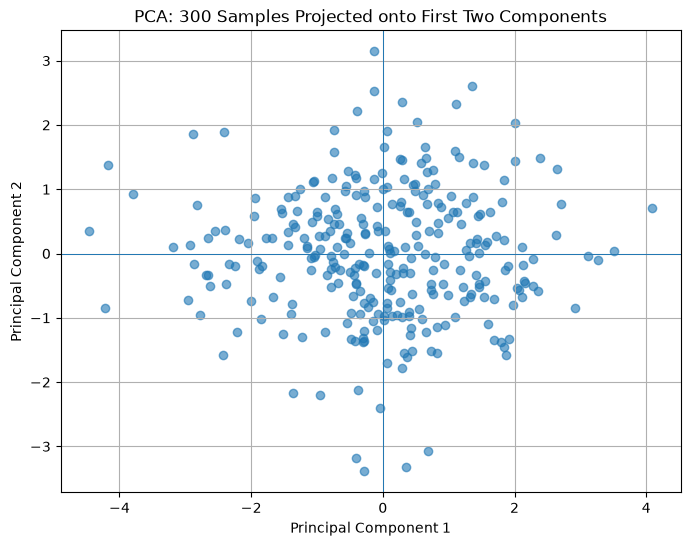

In [13]:
components = eigenvectors[:, :2]

print(components)
print("Components shape:", components.shape)

X_2d = Xs @ components

print("Original data shape:", Xs.shape)
print("Reduced data shape:", X_2d.shape)


plt.figure(figsize=(8, 6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: 300 Samples Projected onto First Two Components")

plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)

plt.grid(True)
plt.show()

In [14]:
cov_numpy = np.cov(Xs.T)

eigenvalues_numpy = np.linalg.eigvalsh(cov_numpy)[::-1]

print("Manual eigenvalues:")
print(eigenvalues)

print("\nNumPy eigenvalues:")
print(eigenvalues_numpy)

print("\nDo they match?")
print(np.allclose(eigenvalues, eigenvalues_numpy))

Manual eigenvalues:
[1.95615664 1.02623593 0.96060016 0.05700728]

NumPy eigenvalues:
[1.95615664 1.02623593 0.96060016 0.05700728]

Do they match?
True
